# PD corporativa a horizontes de uno a cinco años (C02)

**Pregunta:** ¿Pueden cinco muestras anuales de empresas manufactureras polacas dar una estructura temporal de PD corporativa, y cuán bien ordena y calibra la escalera de modelos la quiebra en cada horizonte?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 04 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- leer los cinco archivos de horizonte de C02 y decir por qué sus tasas de eventos no pueden leerse como una curva de PD acumulada;
- ejecutar el AUC del motor sobre muestras reservadas reconstruidas desde los escalones ROC versionados, y comparar la escalera en cada horizonte con la brecha de sobreajuste y los intervalos de DeLong;
- ejecutar Hosmer-Lemeshow, la prueba de nivel y el chi cuadrado sobre tramos en muestras reservadas reconstruidas, y leer qué modelo en qué horizonte está calibrado;
- leer la matriz de transferencia entre archivos y el modelo agrupado con la advertencia de traslape de empresas que limita a ambos.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

from riskvalidation.transitions.intervals import pd_jeffreys as rate_interval
from riskvalidation.validation.calibration import pd_hosmer_lemeshow, pd_jeffreys
from riskvalidation.validation.discrimination import disc_auc
from matplotlib.colors import ListedColormap

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El caso C02 es la PD de empresas deudoras en horizontes de uno a cinco años. Los datos son los "Polish companies bankruptcy data" de UCI (Tomczak, 2016; dueño: UCI Machine Learning Repository; CC BY 4.0, clase de licencia `mirror-allowed`; https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data; DOI 10.24432/C5F600): cinco archivos de razones financieras de empresas manufactureras (64 razones por empresa) con una etiqueta de quiebra, cada uno para un horizonte de pronóstico. La cadena de cálculo ajustó la escalera de siete modelos en cada archivo con una muestra reservada bloqueada y estratificada, y en los cinco archivos apilados. Versionado:

- `data/derived/C02/h1.json` a `h5.json`: un archivo por horizonte, con la discriminación (ROC) de cada modelo, la calibración (tramos de confiabilidad), la revisión de sobreajuste y la estabilidad, la comparación de cada retador con la tarjeta de puntaje, la transferencia entre archivos y la batería de pruebas.
- `data/derived/C02/pooled.json`: lo mismo para los cinco archivos apilados, con la advertencia de traslape de empresas.
- `data/derived/C02/models-polish-horizons.json`: el protocolo del ajuste.

La siguiente celda carga los siete archivos.

In [2]:
# Cargar los cinco archivos de horizonte, el archivo agrupado y el de modelos del caso C02
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C02"
horizons = ["h1", "h2", "h3", "h4", "h5"]
docs = {h: json.loads((derived / f"{h}.json").read_text(encoding="utf-8")) for h in horizons}
pooled = json.loads((derived / "pooled.json").read_text(encoding="utf-8"))
protocol = json.loads((derived / "models-polish-horizons.json").read_text(encoding="utf-8"))["fit"]
policy = rv.default_policy()
LANG = "es"
LIGHT = {"green": "verde", "amber": "ámbar", "red": "roja", "not_evaluated": "ninguna"}
print("definición del evento:", docs["h1"]["outputs"]["counts"]["event_definition"][LANG])
print([docs[h]["outputs"]["counts"]["rows"] for h in horizons])
baked = docs["h1"]["provenance"]["riskvalidation_version"]
print("calculado por riskvalidation", baked, "| instalado", rv.__version__)

definición del evento: Quiebra de la empresa dentro de 1 año de los estados financieros (la etiqueta de clase del archivo 5year.arff)
[5910, 9792, 10503, 10173, 7027]
calculado por riskvalidation 1.0.1 | instalado 1.0.1


## Método

### Paso 1: cinco muestras, no una cohorte

Cada archivo es una muestra de empresas con las razones financieras de un año y el estado de quiebra a un horizonte. Una lectura tentadora toma las cinco tasas de eventos como la probabilidad acumulada de quiebra a uno, dos, tres, cuatro y cinco años, y lee de ellas una estructura temporal, la entrada de una pérdida crediticia esperada de vida. Esa lectura requiere una cohorte de empresas seguida durante cinco años, de modo que la proporción en quiebra solo pueda crecer con el horizonte. Los archivos son **muestras independientes de años de pronóstico distintos**, no una cohorte seguida en el tiempo, y la página de UCI no da identificador de empresa ni fecha. La decisión del producto (G22) es no leer ninguna estructura temporal de ellos. La primera revisión que permiten los datos es la que predice la lectura acumulada: ¿crecen las tasas? La celda calcula la tasa de eventos de cada archivo con el intervalo de Jeffreys del motor para una proporción binomial (Brown, Cai y DasGupta, 2001) y la dibuja contra el horizonte.

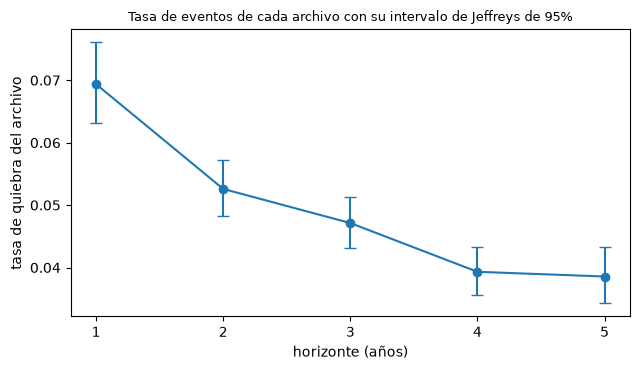

tasas de eventos por horizonte: [0.0694 0.0526 0.0471 0.0393 0.0386]
las tasas crecen con el horizonte: False


In [3]:
# La tasa de eventos de cada archivo con el intervalo de Jeffreys del motor: ¿crecen las tasas con el horizonte?
counts = [docs[h]["outputs"]["counts"] for h in horizons]
intervals = [rate_interval(c["events"], c["rows"]) for c in counts]
rate = np.array([i["estimate"] for i in intervals])
low = rate - np.array([i["lower"] for i in intervals])
high = np.array([i["upper"] for i in intervals]) - rate
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.errorbar(range(1, 6), rate, yerr=[low, high], marker="o", capsize=4)
ax.set_xticks(range(1, 6))
ax.set_xlabel("horizonte (años)")
ax.set_ylabel("tasa de quiebra del archivo")
ax.set_title("Tasa de eventos de cada archivo con su intervalo de Jeffreys de 95%", fontsize=9)
fig.tight_layout()
plt.show()
print("tasas de eventos por horizonte:", np.round(rate, 4))
print("las tasas crecen con el horizonte:", bool((np.diff(rate) > 0).all()))

Las tasas de eventos son 0,0694, 0,0526, 0,0471, 0,0393 y 0,0386 y caen con el horizonte, así que la afirmación de que crecen es Falsa. Los intervalos son lo bastante angostos para que la primera tasa quede claramente sobre la última, y la figura no muestra señal de una curva acumulada: una PD que cae con el horizonte es una muestra distinta en cada punto, no un tiempo distinto. Por eso no se calcula la pérdida crediticia esperada bajo cinco horizontes (el efecto versionado es nulo, con la razón), y todo lo que sigue compara modelos horizonte por horizonte, nunca entre horizontes.

### Paso 2: la escalera en cada horizonte

Los siete modelos son la escalera de los notebooks 03 y 06: una línea base de una variable (P0), la tarjeta de puntaje WoE (P1), una regresión logística penalizada (P2a), árboles penalizados (P2b), una máquina de refuerzo explicable (P3) y dos modelos de árboles potenciados (P4). Cada archivo versiona la ROC de cada modelo en su muestra reservada. Desde los escalones de la ROC, con el número de quiebras y de empresas sanas de la muestra reservada, la celda reconstruye un vector de valores de riesgo y resultados por modelo y horizonte, y se lo entrega a `disc_auc` del motor. Dentro de un escalón se pierde el orden de las empresas, así que los empates cuentan por la mitad. La figura dibuja el AUC de cada modelo contra el horizonte, y la celda imprime el AUC reconstruido y el versionado de la tarjeta de puntaje.

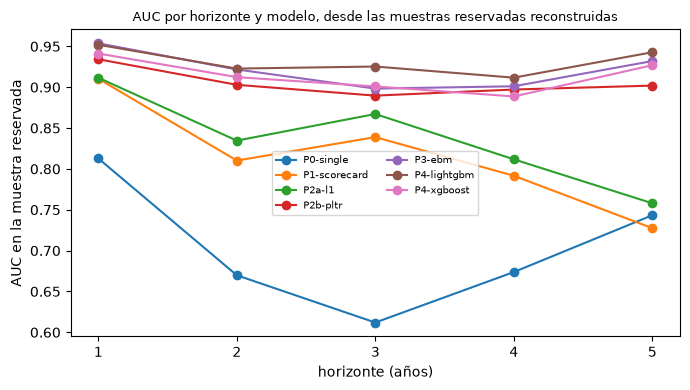

AUC de la tarjeta de puntaje, reconstruido y versionado: h1 0.9104 0.9106
AUC de la tarjeta de puntaje, reconstruido y versionado: h2 0.8102 0.81
AUC de la tarjeta de puntaje, reconstruido y versionado: h3 0.8389 0.8388
AUC de la tarjeta de puntaje, reconstruido y versionado: h4 0.7916 0.792
AUC de la tarjeta de puntaje, reconstruido y versionado: h5 0.7275 0.7279


In [4]:
# Reconstruir la muestra reservada de cada archivo desde los escalones ROC de cada modelo y ejecutar el AUC del motor
auc = {}
for h in horizons:
    o = docs[h]["outputs"]
    n_pos = o["split"]["holdout_events"]
    n_neg = o["split"]["holdout_rows"] - n_pos
    for r in o["rungs"]:
        pos = np.rint(np.diff(r["roc"]["tpr"]) * n_pos).astype(int)
        neg = np.rint(np.diff(r["roc"]["fpr"]) * n_neg).astype(int)
        risk = np.repeat(np.arange(len(pos), 0, -1), pos + neg)
        flags = np.concatenate([np.r_[np.ones(p), np.zeros(q)] for p, q in zip(pos, neg)])
        result = disc_auc(risk, flags, policy=policy, model_id=r["model_id"])
        auc[(h, r["model_id"].split("-", 1)[1])] = (result.metric, r["discrimination"]["auc"])
rungs_ = [r["model_id"].split("-", 1)[1] for r in docs["h1"]["outputs"]["rungs"]]
fig, ax = plt.subplots(figsize=(7, 4))
for rung in rungs_:
    ax.plot(range(1, 6), [auc[(h, rung)][0] for h in horizons], marker="o", label=rung)
ax.set_xticks(range(1, 6))
ax.set_xlabel("horizonte (años)")
ax.set_ylabel("AUC en la muestra reservada")
ax.set_title("AUC por horizonte y modelo, desde las muestras reservadas reconstruidas", fontsize=9)
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()
for h in horizons:
    rebuilt, committed = auc[(h, "P1-scorecard")]
    print("AUC de la tarjeta de puntaje, reconstruido y versionado:", h, round(rebuilt, 4), round(committed, 4))

El AUC reconstruido de la tarjeta de puntaje, 0,9104, 0,8102, 0,8389, 0,7916 y 0,7275, coincide con el versionado dentro de 0,0004. La tarjeta de puntaje cae de 0,91 a un año a 0,73 a cinco, y los modelos más ricos no caen tanto: a cinco años los modelos potenciados llegan a 0,93 a 0,94 donde la tarjeta de puntaje llega a 0,73. Las líneas de la línea base de una variable son las más bajas a tres años. La figura debe leerse con su error de muestreo en mente: la muestra reservada del archivo de cinco años tiene 81 quiebras, y el AUC de la tarjeta de puntaje allí, 0,7275, tiene un intervalo de 95% de cerca de 0,67 a 0,78.

### Paso 3: la brecha de sobreajuste

Un modelo que ordena bien los datos con que se ajustó y peor los datos nuevos ha memorizado ruido. La revisión versionada compara el AUC de la parte de entrenamiento con el AUC de la muestra reservada, y señala al modelo cuando la brecha excede 0,05 puntos de AUC, una convención con nombre del producto (la investigación no da valor; la tolerancia es de uno y medio a tres errores estándar de un AUC con estos tamaños de muestra reservada). La celda calcula la brecha de cada modelo y horizonte desde los AUC versionados de entrenamiento y de muestra reservada y la dibuja como una grilla, con un asterisco donde excede la tolerancia.

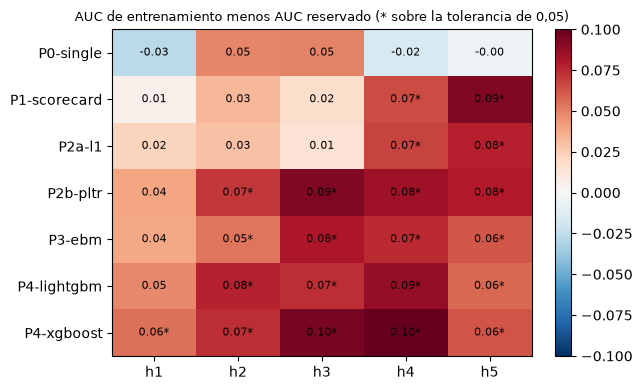

brechas sobre la tolerancia por horizonte: [1 4 4 6 6]


In [5]:
# La brecha entre el AUC de entrenamiento y el de la muestra reservada por modelo y horizonte, sobre la tolerancia
tolerance = docs["h1"]["outputs"]["parameters"][0]["value"]
gap = np.zeros((len(rungs_), len(horizons)))
for j, h in enumerate(horizons):
    for i, r in enumerate(docs[h]["outputs"]["rungs"]):
        gap[i, j] = r["overfit"]["train_auc"] - r["overfit"]["holdout_auc"]
fig, ax = plt.subplots(figsize=(6.5, 4))
image = ax.imshow(gap, cmap="RdBu_r", vmin=-0.1, vmax=0.1, aspect="auto")
for i in range(gap.shape[0]):
    for j in range(gap.shape[1]):
        star = "*" if gap[i, j] > tolerance else ""
        ax.text(j, i, f"{gap[i, j]:.2f}{star}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(5), horizons)
ax.set_yticks(range(len(rungs_)), rungs_)
ax.set_title("AUC de entrenamiento menos AUC reservado (* sobre la tolerancia de 0,05)", fontsize=9)
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()
print("brechas sobre la tolerancia por horizonte:", (gap > tolerance).sum(axis=0))

El número de modelos sobre la tolerancia por horizonte es 1, 4, 4, 6 y 6 de siete. La tarjeta de puntaje misma está dentro de ella en los tres primeros horizontes y sobre ella a cuatro y cinco años (brechas de 0,065 y 0,092), que es donde su AUC es más bajo: menos quiebras se enfrentan a 64 razones, y el ajuste memoriza. Los modelos más ricos sobreajustan más y ordenan mejor, en la muestra reservada, en todos los horizontes; la brecha no dice que sean peores, dice cuán lejos está el AUC de entrenamiento de lo que da una muestra nueva. La línea base de una variable no tiene alerta, por construcción, pues una variable no puede memorizar mucho.

### Paso 4: los retadores frente a la tarjeta de puntaje

Para cada horizonte el archivo compara cada retador con la tarjeta de puntaje, la campeona: la diferencia de AUC con su intervalo de DeLong. El intervalo de DeLong es $\Delta \pm z_{0,975}\,\mathrm{SE}$, de modo que el error estándar se recupera del intervalo, $\mathrm{SE} = (\mathrm{hi} - \mathrm{lo})/(2 z_{0,975})$, y el valor p sigue de la misma ley normal del notebook 03, $p = 2\,(1 - \Phi(|\Delta/\mathrm{SE}|))$. La figura dibuja la diferencia y su intervalo para los cinco retadores en cada uno de los cinco horizontes, y la celda imprime el valor p del retador LightGBM.

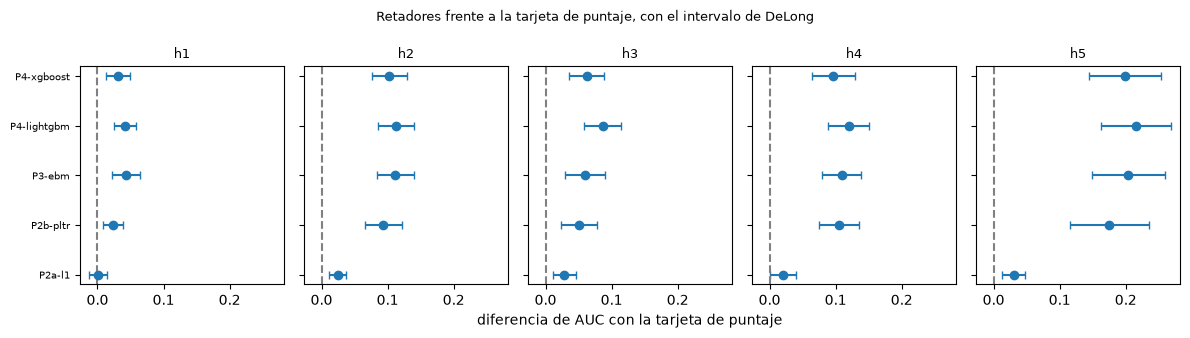

p de DeLong del retador LightGBM por horizonte: h1 1.79e-06
p de DeLong del retador LightGBM por horizonte: h2 6.26e-16
p de DeLong del retador LightGBM por horizonte: h3 1.45e-09
p de DeLong del retador LightGBM por horizonte: h4 1.64e-14
p de DeLong del retador LightGBM por horizonte: h5 2.17e-15


In [6]:
# La diferencia de AUC de cada retador con la tarjeta de puntaje, su intervalo de DeLong y el valor p
z975 = stats.norm.ppf(0.975)
fig, axes = plt.subplots(1, 5, figsize=(12, 3.4), sharex=True)
for ax, h in zip(axes, horizons):
    rows = docs[h]["outputs"]["challenger"]
    names_ = [c["challenger"].split("-", 1)[1] for c in rows]
    diff = np.array([c["auc_diff"] for c in rows])
    lo = diff - np.array([c["auc_diff_ci"]["lo"] for c in rows])
    hi = np.array([c["auc_diff_ci"]["hi"] for c in rows]) - diff
    ax.errorbar(diff, range(len(rows)), xerr=[lo, hi], fmt="o", capsize=3)
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_yticks(range(len(rows)), names_ if h == "h1" else [""] * len(rows), fontsize=7)
    ax.set_title(h, fontsize=9)
axes[2].set_xlabel("diferencia de AUC con la tarjeta de puntaje")
fig.suptitle("Retadores frente a la tarjeta de puntaje, con el intervalo de DeLong", fontsize=9)
fig.tight_layout()
plt.show()
for h in horizons:
    row = next(c for c in docs[h]["outputs"]["challenger"] if c["challenger"].endswith("lightgbm"))
    se = (row["auc_diff_ci"]["hi"] - row["auc_diff_ci"]["lo"]) / (2 * z975)
    p_value = 2 * stats.norm.sf(abs(row["auc_diff"] / se))
    print("p de DeLong del retador LightGBM por horizonte:", h, float(f"{p_value:.3g}"))

La regresión logística penalizada (P2a) empata con la tarjeta de puntaje a un año (diferencia 0,001, p de 0,9) y a cuatro años queda en el borde (0,048); cualquier otro retador la supera con una ganancia de AUC que crece de cerca de 0,04 a un año a cerca de 0,2 a cinco. El valor p de LightGBM es 1,79e-06, 6,26e-16, 1,45e-09, 1,64e-14 y 2,17e-15 de uno a cinco años. El crecimiento con el horizonte es la misma historia de la brecha de sobreajuste vista desde el otro lado: la tarjeta de puntaje es la más débil donde los datos son más escasos. La prueba es pareada y cada intervalo es ancho, de modo que un solo horizonte no puede ordenar a los retadores entre sí.

### Paso 5: calibración, modelo por modelo y horizonte por horizonte

Ordenar es la mitad de la pregunta. Para la calibración, los tramos de confiabilidad versionados dan, para cada modelo y horizonte, diez grupos de empresas por PD con su PD media y su tasa de quiebra observada. Como en el notebook 03, la celda reconstruye la muestra reservada desde ellos, dando a cada empresa la PD de su tramo y a cada tramo su número observado de quiebras, y llama a `pd_hosmer_lemeshow` con diez grupos, lo que reproduce el estadístico versionado. La grilla muestra el valor p de cada modelo y horizonte, pintado con la luz que le da la política.

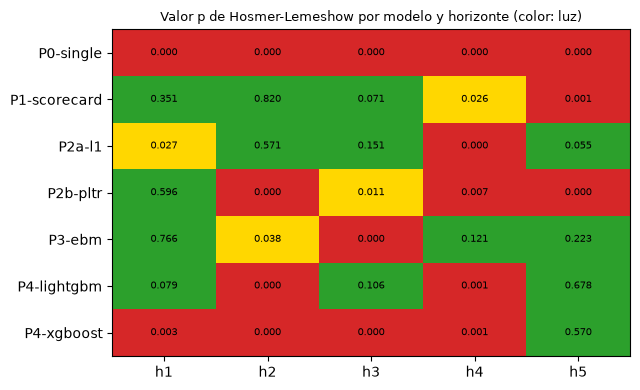

p de Hosmer-Lemeshow de la tarjeta de puntaje por horizonte: [3.511e-01 8.203e-01 7.050e-02 2.580e-02 5.000e-04]


In [7]:
# Reconstruir las tarjetas desde los tramos de confiabilidad de cada modelo y horizonte y ejecutar Hosmer-Lemeshow
colors = {"green": 1, "amber": 2, "red": 3, "not_evaluated": 0}
light_grid = np.zeros((len(rungs_), len(horizons)))
p_grid = np.zeros_like(light_grid)
for j, h in enumerate(horizons):
    for i, r in enumerate(docs[h]["outputs"]["rungs"]):
        bins_ = r["reliability"]
        pd_cards = np.concatenate([np.full(b["n"], b["pd"]) for b in bins_])
        hits = [int(round(b["dr"] * b["n"])) for b in bins_]
        flags = np.concatenate([np.r_[np.ones(k), np.zeros(b["n"] - k)] for b, k in zip(bins_, hits)])
        kw = dict(policy=policy, model_id=r["model_id"], segment="portfolio")
        hl = pd_hosmer_lemeshow(flags, pd_cards, groups=10, **kw)
        p_grid[i, j], light_grid[i, j] = hl.p_value, colors[hl.light.value]
fig, ax = plt.subplots(figsize=(6.5, 4))
cmap = ListedColormap(["lightgray", "tab:green", "gold", "tab:red"])
ax.imshow(light_grid, cmap=cmap, vmin=0, vmax=3, aspect="auto")
for i in range(len(rungs_)):
    for j in range(len(horizons)):
        ax.text(j, i, f"{p_grid[i, j]:.3f}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(5), horizons)
ax.set_yticks(range(len(rungs_)), rungs_)
ax.set_title("Valor p de Hosmer-Lemeshow por modelo y horizonte (color: luz)", fontsize=9)
fig.tight_layout()
plt.show()
print("p de Hosmer-Lemeshow de la tarjeta de puntaje por horizonte:", np.round(p_grid[1], 4))

Ningún modelo está en verde en los cinco horizontes. La línea base de una variable es roja en todas partes (p de 0,0), lo que es natural para un modelo con un puñado de PD distintas. La tarjeta de puntaje es verde a uno, dos y tres años (0,3511, 0,8203, 0,0705), ámbar a cuatro (0,0258) y roja a cinco (0,0005). LightGBM, el mejor ordenador, es verde a uno, tres y cinco años y rojo a dos y cuatro. La calibración de un retador no es una propiedad del modelo sino del modelo en un archivo, y con 81 a 155 quiebras en cada muestra reservada la prueba tiene poca potencia en el borde. La grilla no dice qué modelo es el mejor: dice que la calibración no puede suponerse desde el orden.

### Paso 6: el nivel de la tarjeta de puntaje

Un modelo puede fallar la prueba de ajuste y aun así tener el promedio correcto, que es lo que pregunta la prueba de nivel de Jeffreys de una cola (notebook 03). La celda toma, para la tarjeta de puntaje de cada horizonte, el número de empresas y de quiebras de la muestra reservada y la PD media de sus tramos de confiabilidad, y llama a `pd_jeffreys`. Imprime el valor p con su luz, y el puntaje de Brier versionado del mismo modelo.

In [8]:
# La prueba de nivel de Jeffreys de la tarjeta de puntaje de cada horizonte, con su puntaje de Brier versionado
for h in horizons:
    o = docs[h]["outputs"]
    card = next(r for r in o["rungs"] if r["rung"] == "P1")
    bins_ = card["reliability"]
    n_b = [b["n"] for b in bins_]
    d_b = [int(round(b["dr"] * b["n"])) for b in bins_]
    p_b = [b["pd"] for b in bins_]
    mean_pd = sum(n * p for n, p in zip(n_b, p_b)) / sum(n_b)
    kw = dict(policy=policy, model_id=f"{h}-P1-scorecard", segment="portfolio")
    level = pd_jeffreys(sum(n_b), sum(d_b), mean_pd, **kw)
    print(h, "prueba de nivel de Jeffreys, p:", round(level.p_value, 4), LIGHT[level.light.value])
    print("   Brier versionado:", round(card["calibration"]["brier"], 4))

h1 prueba de nivel de Jeffreys, p: 0.8086 verde
   Brier versionado: 0.0457
h2 prueba de nivel de Jeffreys, p: 0.4518 verde
   Brier versionado: 0.0441
h3 prueba de nivel de Jeffreys, p: 0.3835 verde
   Brier versionado: 0.0385
h4 prueba de nivel de Jeffreys, p: 0.4272 verde
   Brier versionado: 0.0321
h5 prueba de nivel de Jeffreys, p: 0.6061 verde
   Brier versionado: 0.0369


La prueba de nivel es verde en los cinco horizontes (p de 0,8086, 0,4518, 0,3835, 0,4272 y 0,6061), incluidos los horizontes donde Hosmer-Lemeshow es ámbar o rojo. La PD media de la tarjeta de puntaje es correcta en todas partes y su ajuste por grupo es incorrecto en los horizontes más largos: el mismo hallazgo del notebook 04, encontrado aquí con otro par de pruebas. El puntaje de Brier cae de 0,0457 a un año a 0,0321 a cuatro, y luego sube a 0,0369, y sigue a la tasa de eventos más que a la calidad del orden, pues un evento más raro tiene un menor error cuadrático medio incluso para un modelo pobre.

### Paso 7: la misma tarjeta de puntaje en otro archivo

Cada archivo de horizonte versiona un bloque de **transferencia**: un modelo ajustado con la parte de entrenamiento de un archivo y puntuado en la muestra reservada de otro. Es una revisión de robustez tentadora, y el archivo la etiqueta como exploratoria por una razón. La página de UCI no da identificador de empresa, así que la misma empresa puede aparecer en varios archivos (una empresa observada en el tercer año y otra vez en el quinto), y un modelo ajustado en un archivo puede puntuar empresas que ha visto en parte. Cualquier AUC de transferencia puede entonces estar inflado, y no se hace ninguna afirmación fuera de tiempo. La diagonal es el modelo puntuado en su propia muestra reservada. La celda construye la matriz de la tarjeta de puntaje desde los cinco archivos y la dibuja.

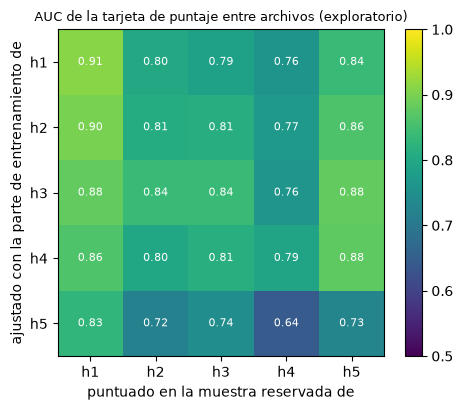

[0.911 0.81  0.839 0.792 0.728]


In [9]:
# Construir la matriz de transferencia de la tarjeta de puntaje (ajustada en un archivo, puntuada en otro) y dibujarla
matrix = np.zeros((5, 5))
for fitted, h in enumerate(horizons):
    for cell in docs[h]["outputs"]["transfer"]["cells"]:
        if cell["rung"] == "P1":
            matrix[fitted, cell["scored_on_years"] - 1] = cell["auc"]
fig, ax = plt.subplots(figsize=(5, 4.2))
image = ax.imshow(matrix, vmin=0.5, vmax=1.0, cmap="viridis")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
ax.set_xticks(range(5), [f"h{j + 1}" for j in range(5)])
ax.set_yticks(range(5), [f"h{i + 1}" for i in range(5)])
ax.set_xlabel("puntuado en la muestra reservada de")
ax.set_ylabel("ajustado con la parte de entrenamiento de")
ax.set_title("AUC de la tarjeta de puntaje entre archivos (exploratorio)", fontsize=9)
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()
print(np.round(np.diag(matrix), 3))

La diagonal, 0,911, 0,81, 0,839, 0,792 y 0,728, es el AUC de la tarjeta de puntaje en su propia muestra reservada. Las celdas fuera de la diagonal son tan altas o más: una tarjeta de puntaje ajustada con el archivo de tres años llega a 0,879 en la muestra reservada de cinco años, donde la ajustada con el archivo de cinco años llega a 0,728. Eso no es evidencia de que el modelo de tres años sea mejor; es la huella esperada de empresas que se repiten entre archivos, y la razón de que el bloque sea exploratorio. La matriz dice que un número fuera de la diagonal no debe informarse como un AUC fuera de muestra.

### Paso 8: los cinco archivos apilados

El archivo agrupado apila los cinco archivos con un indicador de horizonte, así que un solo modelo ve 43.405 empresas-año. Tiene más datos y un intervalo más estrecho, y lleva la misma advertencia completa: si una empresa se repite entre los archivos es desconocido, así que una empresa puede estar en la parte de entrenamiento y en la muestra reservada bajo horizontes distintos. La celda reconstruye la muestra reservada agrupada desde los escalones ROC de cada modelo, y compara el AUC del motor con la media de los cinco AUC por horizonte.

In [10]:
# Reconstruir la muestra agrupada desde los escalones ROC de cada modelo y comparar el AUC del motor con el promedio
po = pooled["outputs"]
n_pos = po["split"]["holdout_events"]
n_neg = po["split"]["holdout_rows"] - n_pos
for r in po["rungs"]:
    pos = np.rint(np.diff(r["roc"]["tpr"]) * n_pos).astype(int)
    neg = np.rint(np.diff(r["roc"]["fpr"]) * n_neg).astype(int)
    risk = np.repeat(np.arange(len(pos), 0, -1), pos + neg)
    flags = np.concatenate([np.r_[np.ones(p), np.zeros(q)] for p, q in zip(pos, neg)])
    result = disc_auc(risk, flags, policy=policy, model_id=r["model_id"])
    name = r["model_id"].split("-", 1)[1]
    mean_five = np.mean([auc[(h, name)][0] for h in horizons])
    print(name, "AUC agrupado, media de los horizontes:", round(result.metric, 4), round(float(mean_five), 4))

P0-single AUC agrupado, media de los horizontes: 0.6519 0.7023
P1-scorecard AUC agrupado, media de los horizontes: 0.8647 0.8157
P2a-l1 AUC agrupado, media de los horizontes: 0.8822 0.8366
P2b-pltr AUC agrupado, media de los horizontes: 0.9166 0.9052
P3-ebm AUC agrupado, media de los horizontes: 0.945 0.9214
P4-lightgbm AUC agrupado, media de los horizontes: 0.9703 0.9309
P4-xgboost AUC agrupado, media de los horizontes: 0.9642 0.914


## Resultados

**Respuesta:** De estos archivos no puede leerse una estructura temporal, y la escalera ordena y calibra de modo desigual entre horizontes. Las cinco tasas de eventos, 0,0694, 0,0526, 0,0471, 0,0393 y 0,0386, caen con el horizonte donde una PD acumulada subiría, así que los archivos son cinco muestras distintas y no se calcula ninguna pérdida de vida. En las muestras reservadas reconstruidas desde los escalones ROC, el motor da a la tarjeta de puntaje un AUC de 0,9104, 0,8102, 0,8389, 0,7916 y 0,7275 de uno a cinco años, mientras los modelos potenciados se mantienen sobre 0,9; los retadores la superan con valores p de DeLong tan pequeños como 2,17e-15 (LightGBM a cinco años), salvo la regresión logística penalizada a un año. La tarjeta de puntaje sobreajusta donde los datos son escasos: la brecha excede la tolerancia a cuatro y cinco años, y 1, 4, 4, 6 y 6 modelos de siete quedan señalados en los cinco horizontes. La calibración por grupo no está garantizada por el orden: el valor p de Hosmer-Lemeshow de la tarjeta de puntaje es 0,3511, 0,8203, 0,0705, 0,0258 y 0,0005, mientras su prueba de nivel es verde en los cinco horizontes (p de 0,8086 a 0,3835). En el archivo apilado el motor da a la tarjeta de puntaje un AUC de 0,8647 frente a un promedio de 0,8157 en los cinco horizontes, una diferencia que el traslape de empresas impide leer como ganancia.

Lo que este notebook no muestra: ninguna afirmación fuera de tiempo, pues los archivos no tienen fecha ni identificador de empresa; la estabilidad por característica de las 64 razones; ni un reajuste, que requiere los archivos crudos bajo la raíz de datos. Con 81 a 155 quiebras por muestra reservada, los intervalos son anchos, que es el principal límite de este caso.

## Resumen

- Cinco archivos de años de pronóstico distintos son cinco muestras, no una cohorte: sus tasas de eventos caen con el horizonte, y no se lee de ellos ninguna estructura temporal ni pérdida de vida.
- La escalera se compara en cada horizonte con el AUC del motor sobre muestras reservadas reconstruidas desde los escalones ROC y con intervalos de DeLong; la brecha de sobreajuste señala los horizontes más largos, donde pocas quiebras se enfrentan a 64 razones.
- Hosmer-Lemeshow reconstruido desde los tramos de confiabilidad muestra que ningún modelo está calibrado en todos los horizontes, y que la prueba de nivel puede ser verde donde la de ajuste es roja.
- Una transferencia entre archivos y un modelo agrupado son exploratorios: sin identificador de empresa no pueden llamarse fuera de muestra.

**Qué probar a continuación.** Toma el horizonte donde la tarjeta de puntaje es más débil, h5, e imprime sus tramos de confiabilidad desde `h5.json` junto a los de LightGBM; luego continúa con el notebook 06, que ejecuta a los retadores del estado del arte contra la tarjeta de puntaje sobre las tarjetas de Taiwán.

## Referencias

- Tomczak, S. (2016), Polish Companies Bankruptcy, UCI Machine Learning Repository (CC BY 4.0), https://doi.org/10.24432/C5F600 (la atribución registrada en `data/derived/C02/raw-sources.txt`). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data
- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach, Biometrics 44(3). https://doi.org/10.2307/2531595
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf